[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/5_local_metric_field.ipynb)

# Local metric field

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the local metric field around a reference image: perturb it along the two leading eigenvectors of the Inception model's G(x), and draw the projected metrics of Inception and ResNet-50 as ellipses (paper Fig. 5).

* **Requirements**: the datasets and checkpoints (see the README) and a GPU.

* **Time**: about 26 min for the default 5 x 5 grid, both areas and both models, on one GPU.

<details><summary>Details</summary>

* **What is drawn**: at every perturbed image, the metrics of the Inception and ResNet-50 models are projected onto the same 2-D subspace (A: G(x), B: the Fisher metric J(x); V1 left, V4 right).
* **Reading it**: ellipses that vary smoothly and agree between the two models mean that the geometry reflects the neural code and not the fitted model; ellipses that jump around and disagree mean it reflects the model. In the paper, G(x) is stable and J(x) is not.
* **Cost**: every grid point of every model needs one G(x) estimate (about 15 s on an RTX 5090); J(x) takes seconds. Processes sharing one GPU are slower than one, so a single background process is used.
* The job and its launcher are in `multigeom.pipeline.metric_field_job`, the computation in `multigeom.pipeline.metric_field`, the drawing in `figures/fig5.py`. This notebook only sets parameters and calls them.

</details>

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom` and `diffusers`; elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom
    %pip install -q "diffusers>=0.30,<0.38"     # the diffusion model of this notebook

CPU times: user 5 μs, sys: 1 μs, total: 6 μs
Wall time: 7.15 μs


### 1.2. Imports and parameters: what to compute

Set `GRID_SIZE`, `AREAS`, `METRICS` and the reference image `IMG_IDX` in the next cell. Typical settings:

| Case | `GRID_SIZE` | `AREAS` | `METRICS` | Time on one RTX 5090 |
|---|---|---|---|---|
| quick check | 3 | `("V1",)` | `("J",)` | seconds |
| G(x) and J(x) for one area | 3 | `("V1",)` | `("G", "J")` | about 5 min |
| the full figure (default) | 5 | `("V1", "V4")` | `("G", "J")` | about 25 min (measured) |

<details><summary>Details</summary>

* `IMG_IDX` is the reference image, an index into the TinyImageNet validation images (the same order as the G(x) estimation of notebook 4).
* The grid is `GRID_SIZE` x `GRID_SIZE` images around the reference, `x(a, b) = x0 + a * e1 * v1 + b * e2 * v2`, where `v1`, `v2` are the leading eigenvectors of the metric being drawn at the reference image (Inception).
* **Step sizes** (`STEPS`, per metric). G uses `0.5 sqrt(lambda)`, about 0.3. J(x) has far larger eigenvalues, so the same rule would give steps of 5 to 7: the perturbed images are clipped to [-1, 1], the local structure is lost, and off-centre the ResNet-50 ellipses come out larger than the Inception ones. A small fixed step of 0.3, the size of G's steps, keeps the field smooth and the Inception ellipses outside the ResNet-50 ones, as in the paper's panel B. The paper does not state its step sizes, so this is a choice; `multigeom.pipeline.metric_field` uses `0.5 sqrt(lambda)` for both metrics by default, and this notebook runs it once per metric.
* **Reference image 64.** The paper does not state its reference image, and the field depends strongly on it. In the paper's panel B the central ellipses are horizontal and, towards the edges, the ellipses turn so that they point radially away from the centre, with Inception outside ResNet-50. We scanned the 200 test images with six perturbation settings: image 64 with a fixed step of 0.2 to 0.3 is the only one that is both radial (score 0.81 in V1 and 0.91 to 0.94 in V4, where 1 is perfectly radial and random orientations give 0.64) and has Inception clearly outside ResNet-50 (area ratio 5 to 6 in V1, 2.5 to 3 in V4). Image 0, the default of `multigeom.pipeline.metric_field`, shows the radial pattern only for ResNet-50. Panel B, the Fisher metric J(x), does not depend on the diffusion model, and it is unchanged with the 200-epoch checkpoints.
* Ellipse convention: width `2 sqrt(mu_max)` and height `2 sqrt(mu_min)` of the projected 2 x 2 matrix, angle of the major axis from the `v1` axis. Within each plot all ellipses share one scale, so sizes compare across grid points and models, not between plots.
* **Not reproduced:** in the paper's panel A the V1 ellipses of G(x) are strongly elongated. Here G(x) is nearly isotropic in the plane (over the 200 test images, the median ratio of the two leading eigenvalues of G(x) is 1.55 for Inception in V1), so the ellipses are nearly round. The diffusion checkpoints are the 200-epoch ones of the paper, so the cause lies elsewhere, for example a different definition or estimator setting used for the paper.

</details>

time: <1 sec

In [2]:
%%time

# import built-in packages
import os, sys
from pathlib import Path
import importlib

# move to the repository root (the folder containing environment.yml): data/ and runs/
# are read from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

sys.path.insert(0, str(root))  # the figures/ folder of this repository

# import custom packages
from multigeom.utils import show_figure
from figures.fig5 import make_figure
from multigeom.pipeline import metric_field_job as lmf

importlib.reload(lmf)  # update the modules without restarting the kernel

# parameters (see the table above)
# reference image (index into the TinyImageNet validation images); 64: best match of
# the paper's panel B
IMG_IDX = 64
GRID_SIZE = 5  # odd: the grid is GRID_SIZE x GRID_SIZE images

# perturbation size per metric: (rule, size)
#   "sqrt_lambda": step_i = size * sqrt(lambda_i)   (about 0.3 for G)
#   "fixed": step_i = size   (J's eigenvalues are far larger)
STEPS = {"G": ("sqrt_lambda", 0.5), "J": ("fixed", 0.3)}
AREAS = ("V1", "V4")  # ("V1",) for a quicker run
METRICS = ("G", "J")  # G(x) is the expensive one
DEVICE = "gpu"  # "gpu" | "cpu" (a CPU is far slower)

# the job: what to compute
job = lmf.MetricFieldJob(
    img_idx=IMG_IDX,
    grid_size=GRID_SIZE,
    steps=STEPS,
    areas=AREAS,
    metrics=METRICS,
    device=DEVICE,
)

RUN = True  # False: only print the estimate. True: launch the computation.
RESTART = True  # True: first delete this job's results, to recompute them from scratch

print(job)
lmf.print_estimate(job)

MetricFieldJob(img_idx=64, grid_size=5, steps={'G': ('sqrt_lambda', 0.5), 'J': ('fixed', 0.3)}, reference_encoder='inception', other_encoder='resnet50', areas=('V1', 'V4'), metrics=('G', 'J'), device='gpu')
102 G(x) estimates and 102 J(x) evaluations: about 26.0 min on one GPU (a G(x) estimate takes ~15 s on an RTX 5090).
CPU times: user 3.23 s, sys: 91.3 ms, total: 3.33 s
Wall time: 796 ms


MetricFieldEstimate(g_estimates=102, j_evaluations=102, seconds=1560.6)

### 1.3. Download checkpoints and data

The trained encoders and diffusion models come from Hugging Face; TinyImageNet gives the test images (240 MB the first time).

time: <1 sec

In [3]:
%%time

from huggingface_hub import snapshot_download
from multigeom.datasets import download_tinyimagenet

# the trained encoders and diffusion models (files that are already there are kept; the
# archive/ folder of older checkpoints is skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns="archive/*",
)

# TinyImageNet, for the test images (240 MB the first time, nothing afterwards)
download_tinyimagenet()

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 554 ms, sys: 78.1 ms, total: 632 ms
Wall time: 727 ms


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 2. Run

The computation runs in a background process: it survives a kernel crash, and launching again computes only what is missing. Log: `runs/logs/metric_field.log`. Set `RESTART = True` above to recompute from scratch (this deletes only this job's result files).

time: <1 sec

In [4]:
%%time
if not RUN:
    print("RUN is False: nothing was started. Set RUN = True above to launch.")
else:
    # 1. optionally delete this job's results
    if RESTART:
        lmf.clear_results(job)

    # 2. launch the background process, unless everything is computed
    if lmf.is_complete(job):
        proc = None
        print("All parts are already computed: nothing to launch.")
    else:
        proc = lmf.launch(job)
        print(proc)

deleted 0 result file(s)
{'pid': 165562, 'log': '/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs/logs/metric_field.log', 'device': 'gpu'}
CPU times: user 4.05 ms, sys: 103 μs, total: 4.15 ms
Wall time: 4.3 ms


### 2.1. Wait for the computation

This cell waits for the process and shows a progress bar over the (metric, area) parts. **Interrupting the kernel stops the process**; finished parts are kept.

<details><summary>Details</summary>

The bar moves when a part is finished, so with one area it moves only a few times. To only stop waiting, pass `stop_on_interrupt=False`. If the kernel dies, the process keeps running; `lmf.stop()` stops it from a later session.

</details>

time: 24 min

In [5]:
%%time 

# wait for the background process (a progress bar over the parts)
lmf.wait(job, globals().get("proc"))

local metric field: 100%|█| 4/4 [25:30<00:00, 382.51s/part, 0 process running; 4/4 (metric, area) pa

all parts done
CPU times: user 138 ms, sys: 118 ms, total: 257 ms
Wall time: 25min 30s


True

## 3. Plot Fig. 5

A: G(x), B: the Fisher metric J(x); the reference (Inception) is drawn solid blue and the comparison (ResNet-50) dashed orange; parts that were not computed are left blank.

time: <1 sec

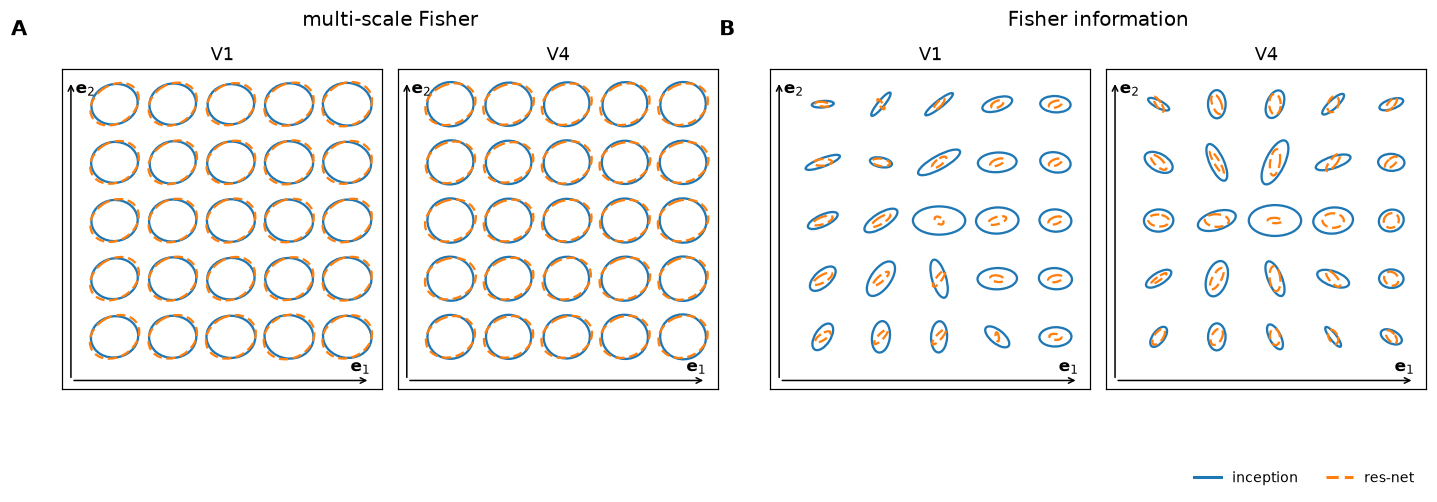

CPU times: user 208 ms, sys: 8.79 ms, total: 217 ms
Wall time: 216 ms


In [6]:
%%time

# draw the ellipses of the parts that are finished
if lmf.progress(job)[0] == 0:
    print("Nothing to plot yet: run the cells above first.")
else:
    show_figure(make_figure(lmf.load_records(job)))